# Nearest Neighbors Classification: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/neighbors/plot_classification.py`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/neighbors/plot_classification.html))
at scikit-learn `4358542a1bd39af2e7e1cbace8b9fed067473c5b`.

**Scenario:** `Pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=11))` on two iris features
(sepal length/width), stratified `train_test_split(random_state=0)`, refitted after
`set_params(knn__weights=...)` for `"uniform"` and `"distance"`, then predicted on the
`DecisionBoundaryDisplay` grid (100×100 points, eps=1 around `X_test`).

**Beyond the gallery (composition, work-plan step 5):** `kneighbors` and `predict_proba` of the fitted
step, `cross_val_score` of the pipeline, `GridSearchCV` over `n_neighbors` × `weights` (on the classifier with
StandardScaler-transformed rows of the bundled, tie-free wine data, because a search over the pipeline itself does not
compile yet and iris ties make candidate scores backend-dependent), and `clone`.

**Adaptations:**
- Bundled iris, as in the example; the split and the grid are computed in Python and shared, so both sides
  fit and predict on identical rows.
- Labels are Float64 class codes (`KNeighborsClassifier[DType.float64]` with the default `NDArray` label domain).
- `clf.set_params(knn__weights=w)` becomes `clf.estimator.set_params(weights=w)`: Moxie pipelines expose typed
  steps instead of `step__param` string routing (documented in `docs/interfaces.md`).
- The notebook kernel uses the installed scikit-learn wheel; its `DecisionBoundaryDisplay` lacks the pinned
  `target_colors_`, so the scatter colormap is built directly (plot styling only).
- `DecisionBoundaryDisplay` is not used on the Moxie side; the Moxie grid predictions are drawn with
  `pcolormesh` from the same grid.
- Moxie searches need explicit typed adapters and scorers (model_selection #3 parts 3 and 4); folds are
  materialized `KFold(5)` splits.

**Determinism:** the reference is deterministic (fixed split seed, exact neighbor search). Iris sepal
measurements have 0.1 cm resolution, so many grid points are equidistant from several training rows. scikit-learn
documents that the order of equidistant neighbors is unspecified, and Moxie breaks ties by ascending training index;
grid points whose 11th/12th neighbors tie at the cut-off can therefore legitimately differ. The checks
below count such points separately instead of hiding them.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("neighbors/plot_classification")

## 1. scikit-learn (Python reference)

The official code, with the figure kept small.

/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was

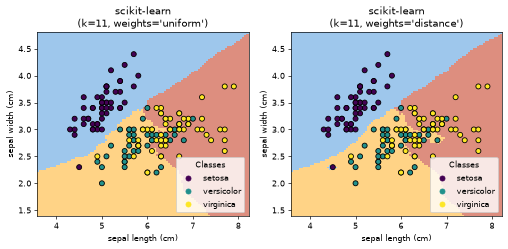

{'uniform': 0.7105, 'distance': 0.6316}


In [2]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris(as_frame=True)
X = iris.data[["sepal length (cm)", "sepal width (cm)"]]
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=0)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

clf = Pipeline(
    steps=[("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=11))]
)

from sklearn.inspection import DecisionBoundaryDisplay

sk = {}
_, axs = plt.subplots(ncols=2, figsize=(10, 4), dpi=60)
for ax, weights in zip(axs, ("uniform", "distance")):
    clf.set_params(knn__weights=weights).fit(X_train, y_train)
    disp = DecisionBoundaryDisplay.from_estimator(
        clf, X_test, response_method="predict", plot_method="pcolormesh",
        xlabel=iris.feature_names[0], ylabel=iris.feature_names[1], shading="auto", alpha=0.5, ax=ax,
    )
    # The notebook kernel runs the installed scikit-learn wheel, whose display lacks the pinned
    # `target_colors_` attribute; the pinned default viridis class colors are used directly.
    cmap = mpl.colors.ListedColormap(plt.cm.viridis(np.linspace(0, 1, 3)))
    scatter = disp.ax_.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y, cmap=cmap, edgecolors="k")
    disp.ax_.legend(scatter.legend_elements()[0], iris.target_names, loc="lower right", title="Classes")
    _ = disp.ax_.set_title(f"scikit-learn\n(k={clf[-1].n_neighbors}, weights={weights!r})")
    grid = np.c_[disp.xx0.ravel(), disp.xx1.ravel()]
    dist, ind = clf[-1].kneighbors(clf[0].transform(X_test.to_numpy()))
    sk[weights] = dict(grid_pred=disp.response.ravel(), test_pred=clf.predict(X_test.to_numpy()),
                       proba=clf.predict_proba(X_test.to_numpy()), score=clf.score(X_test.to_numpy(), y_test),
                       dist=dist, ind=ind, classes=clf[-1].classes_)
plt.show()
xx0, xx1 = disp.xx0, disp.xx1
print({w: round(v["score"], 4) for w, v in sk.items()})
nb.share(X_train=X_train.to_numpy(), y_train=y_train.to_numpy().astype(float), X_test=X_test.to_numpy(),
         y_test=y_test.to_numpy().astype(float), grid=grid)

### Tie diagnosis on the grid (reference side)

For each grid point, is the 11th-nearest scaled training distance equal to the 12th? Only those points may legitimately differ.

In [3]:
from sklearn.neighbors import NearestNeighbors
scaled_train = clf[0].transform(X_train.to_numpy())  # clf holds the weights="distance" fit
nn12 = NearestNeighbors(n_neighbors=12, algorithm="brute").fit(scaled_train)
d12, _ = nn12.kneighbors(clf[0].transform(grid))
cutoff_tie = np.isclose(d12[:, 10], d12[:, 11], rtol=0, atol=1e-12)
d12t, _ = nn12.kneighbors(clf[0].transform(X_test.to_numpy()))
test_tie = np.isclose(d12t[:, 10], d12t[:, 11], rtol=0, atol=1e-12)
print("grid points with a tie at the k-th neighbor:", int(cutoff_tie.sum()), "of", len(grid))
print("test points with a tie at the k-th neighbor:", int(test_tie.sum()), "of", len(test_tie))
# scikit-learn's own backends choose different tied neighbors on these rows:
backend_sets = {a: np.sort(KNeighborsClassifier(11, algorithm=a).fit(scaled_train, y_train).kneighbors(
    clf[0].transform(X_test.to_numpy()))[1], axis=1) for a in ("brute", "kd_tree", "ball_tree")}
print("test rows where sklearn brute and kd_tree pick different neighbor sets:",
      int((backend_sets["brute"] != backend_sets["kd_tree"]).any(axis=1).sum()),
      "| brute vs ball_tree:", int((backend_sets["brute"] != backend_sets["ball_tree"]).any(axis=1).sum()))

/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


grid points with a tie at the k-th neighbor: 1115 of 10000
test points with a tie at the k-th neighbor: 17 of 38
test rows where sklearn brute and kd_tree pick different neighbor sets: 9 | brute vs ball_tree: 8


/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was

### Composition reference: cross-validation, grid search, clone

In [4]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score

sk_cv = cross_val_score(clf.set_params(knn__weights="uniform"), X_train, y_train, cv=KFold(5))
ks = [1, 3, 5, 7, 9, 11, 15]
# The grid search runs on the classifier with StandardScaler-transformed rows (the Moxie search cannot
# take the pipeline itself yet; see section 2). It uses the bundled wine data, whose 13 continuous
# features have no tied neighbor distances, so every candidate score is comparable exactly.
from sklearn.datasets import load_wine
X_wine, y_wine = load_wine(return_X_y=True)
order = np.random.RandomState(0).permutation(len(y_wine))  # wine rows are sorted by class
Xw_train, Xw_test, yw_train, yw_test = train_test_split(X_wine[order], y_wine[order].astype(float), random_state=0)
scaler = StandardScaler().fit(Xw_train)
scaled_train_w, scaled_test_w = scaler.transform(Xw_train), scaler.transform(Xw_test)
search = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": ks, "weights": ["uniform", "distance"]}, cv=KFold(5))
search.fit(scaled_train_w, yw_train)
sk_search = dict(mean=search.cv_results_["mean_test_score"], rank=search.cv_results_["rank_test_score"],
                 best_k=search.best_params_["n_neighbors"], best_w=search.best_params_["weights"],
                 best_score=search.best_score_, refit_pred=search.predict(scaled_test_w),
                 order=np.array([p["n_neighbors"] + 100 * (p["weights"] == "distance") for p in search.cv_results_["params"]], float))
print("cross_val_score:", np.round(sk_cv, 4))
print("best:", search.best_params_, round(search.best_score_, 4))
print("clone of fitted pipeline is unfitted:", not hasattr(clone(clf)[-1], "classes_"))
nb.share(ks=np.asarray(ks, float), scaled_train=scaled_train_w, y_wine_train=yw_train, scaled_test=scaled_test_w)

cross_val_score: [0.7826 0.6957 0.9091 0.8182 0.7727]
best: {'n_neighbors': 1, 'weights': 'uniform'} 0.9624
clone of fitted pipeline is unfitted: True


## 2. Moxie (native Mojo)

The same pipeline through `moxie.pipeline.make_pipeline`; the weights are switched with the new keyword `set_params` on the fitted step and the pipeline is refitted.

In [5]:
%%mojo knn_iris
from moxie.pipeline import make_pipeline
from moxie.preprocessing import StandardScaler
from moxie.neighbors import KNeighborsClassifier
from moxie_nb_io import load, save, save_floats, save_ints


def main() raises:
    var X_train = load("X_train")
    var y_train = load("y_train")
    var X_test = load("X_test")
    var y_test = load("y_test")
    var grid = load("grid")
    var clf = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=11))
    for w in ["uniform", "distance"]:
        var weights = String(w)
        _ = clf.estimator.set_params(weights=weights)
        _ = clf.fit(X_train, y_train)
        save(weights + "_grid", clf.predict(grid))
        save(weights + "_test", clf.predict(X_test))
        save(weights + "_proba", clf.predict_proba(X_test)[0].copy())
        save_floats(weights + "_score", [clf.score(X_test, y_test)])
        var neighbors = clf.estimator.kneighbors(clf.transformer.transform(X_test))
        save_ints(weights + "_ind", neighbors.indices)
        save(weights + "_dist", neighbors.distances.value())
        save(weights + "_classes", clf.estimator.classes_[0])
        print(weights, "fit method:", clf.estimator._fit_method, "| effective metric:", clf.estimator.effective_metric_,
              "| n_samples_fit_:", clf.estimator.n_samples_fit_)

uniform fit method: kd_tree | effective metric: euclidean | n_samples_fit_: 112
distance fit method: kd_tree | effective metric: euclidean | n_samples_fit_: 112


Composition: `cross_val_score` over the pipeline, `GridSearchCV` over `n_neighbors` × `weights` on the classifier with scaled wine rows (typed adapter, configured through the new keyword `set_params`), and `clone`.

In [6]:
%%mojo knn_search
from numojo import NDArray
from moxie.base import SupervisedEstimator, Predictor, clone
from moxie.model_selection import GridSearchCV, KFold, IndexArray, IndexSplit, SearchAdapter, SearchScorer, cross_val_score
from moxie.model_selection._evaluation import TypedScorer
from moxie.model_selection._validation import CVAdapter
from moxie.model_selection._split import _rows
from moxie.pipeline import make_pipeline
from moxie.preprocessing import StandardScaler
from moxie.neighbors import KNeighborsClassifier
from moxie_nb_io import load, save, save_floats

comptime Dense = NDArray[DType.float64]


def kfold(n: Int) raises -> List[IndexSplit]:
    var cursor = KFold(5).split(n)
    var out = List[IndexSplit]()
    while True:
        var pair = cursor.next()
        if not pair:
            break
        out.append(pair.value().copy())
    return out^


def accuracy(prediction: Dense, y: Dense) raises -> Float64:
    var hits = 0
    for i in range(y.size):
        if prediction.unsafe_get(i) == y.unsafe_get(i):
            hits += 1
    return Float64(hits) / Float64(y.size)


struct Accuracy[E: SupervisedEstimator & Predictor & Deinitable](TypedScorer):
    # sklearn's default classifier scorer (mean accuracy of predict), generic so the
    # pipeline type is never named (see model_selection tracking PR #3 part 1).
    comptime Estimator = Self.E
    comptime Input = Dense
    comptime Target = Dense
    comptime Metadata = Optional[Dense]

    def __init__(out self):
        pass

    def score(self, estimator: Self.E, X: Dense, y: Dense, metadata: Optional[Dense]) raises -> Float64:
        return accuracy(rebind_var[Dense](estimator.predict(rebind[Self.E.Input](X))), y)


struct Rows[E: SupervisedEstimator & Predictor & Deinitable](CVAdapter):
    comptime Scorer = Accuracy[Self.E]

    def __init__(out self):
        pass

    def n_samples(self, X: Dense, y: Dense) raises -> Int:
        return X.shape[0]

    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return _rows(X, rows)

    def target_rows(self, y: Dense, rows: IndexArray) raises -> Dense:
        return _rows(y, rows)

    def metadata_rows(self, metadata: Optional[Dense], rows: IndexArray) raises -> Optional[Dense]:
        return None

    def fit(self, mut estimator: Self.E, X: Dense, y: Dense, metadata: Optional[Dense]) raises:
        _ = estimator.fit(rebind[Self.E.Input](X), rebind[Self.E.Target](y))


def cv_scores[E: SupervisedEstimator & Predictor & Deinitable](estimator: E, X: Dense, y: Dense) raises -> Dense:
    return cross_val_score[Rows[E]](estimator, X, y, Rows[E](), Accuracy[E](), kfold(X.shape[0]), None, None)


struct KnnAccuracy(SearchScorer):
    comptime Estimator = KNeighborsClassifier[]
    comptime Input = Dense
    comptime Target = Dense
    comptime Metadata = Optional[Dense]

    def __init__(out self):
        pass

    def score(self, estimator: KNeighborsClassifier[], X: Dense, y: Dense, metadata: Optional[Dense]) raises -> Float64:
        return estimator.score(X, y)


struct KnnSearch(SearchAdapter):
    comptime Scorer = KnnAccuracy
    comptime Value = Float64

    def __init__(out self):
        pass

    def n_samples(self, X: Dense, y: Dense) raises -> Int:
        return X.shape[0]

    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return _rows(X, rows)

    def target_rows(self, y: Dense, rows: IndexArray) raises -> Dense:
        return _rows(y, rows)

    def metadata_rows(self, metadata: Optional[Dense], rows: IndexArray) raises -> Optional[Dense]:
        return None

    def fit(self, mut estimator: KNeighborsClassifier[], X: Dense, y: Dense, metadata: Optional[Dense]) raises:
        _ = estimator.fit(X, y)

    def configure(self, mut estimator: KNeighborsClassifier[], params: Dict[String, Float64]) raises:
        # Search values are typed Float64: weights 0/1 encode "uniform"/"distance".
        for key in params.keys():
            if key == "n_neighbors":
                _ = estimator.set_params(n_neighbors=Int(params[key]))
            elif key == "weights":
                _ = estimator.set_params(weights=String("distance") if params[key] == 1 else String("uniform"))
            else:
                raise Error("ValueError: unknown parameter " + key)

    def default_scorer(self) raises -> KnnAccuracy:
        return KnnAccuracy()

    def default_cv(self, X: Dense, y: Dense) raises -> List[IndexSplit]:
        return kfold(X.shape[0])


def main() raises:
    var X_train = load("X_train")
    var y_train = load("y_train")
    var X_test = load("X_test")
    var ks = load("ks")
    var pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=11))
    save("cv_scores", cv_scores(pipe, X_train, y_train))

    # GridSearchCV over the classifier on StandardScaler-transformed rows (the reference
    # cell runs the same search on the same transformed rows).
    var scaled_train = load("scaled_train")
    var y_wine_train = load("y_wine_train")
    var scaled_test = load("scaled_test")
    var grid = Dict[String, List[Float64]]()
    var values = List[Float64]()
    for i in range(ks.size):
        values.append(Float64(ks.unsafe_get(i)))
    grid["n_neighbors"] = values^
    grid["weights"] = [0.0, 1.0]
    var search = GridSearchCV[KnnSearch](KNeighborsClassifier(), grid, KnnSearch(), cv=kfold(scaled_train.shape[0]))
    search.fit(scaled_train, y_wine_train, None, None)
    var results = search.cv_results_()
    save("search_mean", results.mean_test_score)
    var best = search.best_params_()
    save_floats("search_best", [best["n_neighbors"], best["weights"], search.best_score_()])
    save("search_refit_pred", search.best_estimator_().predict(scaled_test))
    var keys = List[Float64]()
    for i in range(len(results.params)):
        keys.append(results.params[i]["n_neighbors"] + 100 * results.params[i]["weights"])
    save_floats("search_order", keys)

    _ = pipe.fit(X_train, y_train)
    var copy = clone(pipe)
    print("clone of fitted pipeline is unfitted:", not copy.__sklearn_is_fitted__(),
          "| original still fitted:", pipe.__sklearn_is_fitted__())

clone of fitted pipeline is unfitted: True | original still fitted: True


GridSearchCV whose estimator is the pipeline itself needs a search scorer naming the `Pipeline[...]` type. On Mojo 1.0 that type cannot be named outside its generic context (model_selection tracking PR #3 part 1), and the compiler crashes. This cell records the failure.

In [7]:
%%mojo knn_pipeline_search --expect-fail
from numojo import NDArray
from moxie.pipeline import Pipeline, make_pipeline
from moxie.preprocessing import StandardScaler
from moxie.neighbors import KNeighborsClassifier
from moxie.model_selection import SearchScorer
from moxie_nb_io import load

comptime Dense = NDArray[DType.float64]
comptime KnnPipe = Pipeline[StandardScaler[DType.float64], KNeighborsClassifier[DType.float64]]


struct PipeAccuracy(SearchScorer):
    comptime Estimator = KnnPipe
    comptime Input = Dense
    comptime Target = Dense
    comptime Metadata = Optional[Dense]

    def __init__(out self):
        pass

    def score(self, estimator: KnnPipe, X: Dense, y: Dense, metadata: Optional[Dense]) raises -> Float64:
        return estimator.score(X, y)


def main() raises:
    var X = load("X_train")
    var y = load("y_train")
    var pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=11))
    _ = pipe.fit(X, y)
    print(PipeAccuracy().score(pipe, X, y, None))

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/neighbors/plot_classification/knn_pipeline_search.mojo:30:32: error: cannot implicitly convert 'Pipeline[StandardScaler, KNeighborsClassifier]' value to 'Pipeline[StandardScaler, KNeighborsClassifier]'
    print(PipeAccuracy().score(pipe, X, y, None))
                               ^~~~
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/neighbors/plot_classification/knn_pipeline_search.mojo:22:16: error: cannot implicitly convert 'Pipeline[StandardScaler, KNeighborsClassifier]' value to 'Pipeline[StandardScaler, KNeighborsClassifier]'
        return estimator.score(X, y)
               ^~~~~~~~~
Please submit a bug report to https://github.com/modular/modular/issues and include the crash backtrace along with all the relevant source codes.
Stack dump:
0.	Program arguments: mojo build -O3 --fp-mode=contract=off -I /home/strge

## 3. Side by side and parity

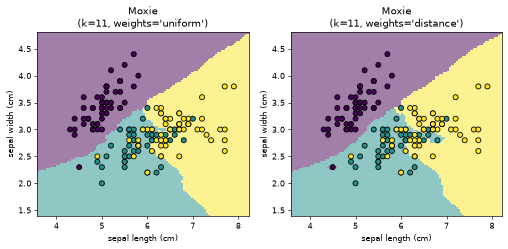

In [8]:
mx = nb.results["knn_iris"]
fig, axs = plt.subplots(ncols=2, figsize=(10, 4), dpi=60)
for ax, weights in zip(axs, ("uniform", "distance")):
    ax.pcolormesh(xx0, xx1, mx[weights + "_grid"].reshape(xx0.shape), cmap=cmap, alpha=0.5, shading="auto")
    ax.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y, cmap=cmap, edgecolors="k")
    ax.set(title=f"Moxie\n(k=11, weights={weights!r})", xlabel=iris.feature_names[0], ylabel=iris.feature_names[1])
plt.show()
moxie_nb.side_by_side(sklearn={w: round(sk[w]["score"], 6) for w in sk},
                      moxie={w: round(float(mx[w + "_score"][0]), 6) for w in sk})
TIE = ("iris sepal values have 0.1 cm resolution; when the 11th and 12th scaled distances tie, sklearn leaves "
       "the neighbor choice unspecified (its brute, kd_tree and ball_tree backends disagree on these rows, see the "
       "diagnosis cell) and Moxie takes the lowest training index (family docs, estimators.md). Against the compiled "
       "pinned reference all 38 test predictions are equal; the notebook kernel runs the installed wheel")
for w in ("uniform", "distance"):
    nb.compare(f"{w}: classes_", sk[w]["classes"].astype(float), mx[w + "_classes"], exact=True)
    diff = sk[w]["grid_pred"].astype(float) != mx[w + "_grid"]
    nb.compare(f"{w}: grid predict at points without a k-th neighbor tie", sk[w]["grid_pred"][~cutoff_tie].astype(float),
               mx[w + "_grid"][~cutoff_tie], exact=True)
    nb.note(f"{w}: grid predict at tied points", "PASS" if not diff[cutoff_tie].any() else "ADAPTED",
            f"{int(diff[cutoff_tie].sum())} of {int(cutoff_tie.sum())} tied grid points differ; {TIE}")
    nb.compare(f"{w}: test predict on rows without a k-th tie", sk[w]["test_pred"][~test_tie].astype(float),
               mx[w + "_test"][~test_tie], exact=True)
    nb.compare(f"{w}: test predict_proba on rows without a k-th tie", sk[w]["proba"][~test_tie], mx[w + "_proba"][~test_tie],
               rtol=1e-12, atol=1e-12,
               reason="vote fractions (uniform) or inverse-distance shares (distance) in Float64; only summation order differs")
    tdiff = sk[w]["test_pred"].astype(float) != mx[w + "_test"]
    nb.note(f"{w}: test predict on tied rows", "PASS" if not tdiff[test_tie].any() else "ADAPTED",
            f"{int(tdiff[test_tie].sum())} of {int(test_tie.sum())} tied test rows differ; {TIE}")
    score_note = "equal" if sk[w]["score"] == float(mx[w + "_score"][0]) else (
        f"sklearn {sk[w]['score']:.4f} vs Moxie {float(mx[w + '_score'][0]):.4f}, entirely from tied rows")
    nb.note(f"{w}: score (accuracy) on all 38 test rows", "PASS" if score_note == "equal" else "ADAPTED", score_note)
    nb.compare(f"{w}: kneighbors distances on scaled X_test", sk[w]["dist"], mx[w + "_dist"].reshape(sk[w]["dist"].shape),
               rtol=1e-12, atol=1e-12, reason="Euclidean distances of StandardScaler output; scaler rounding only")
    same = (np.sort(sk[w]["ind"], axis=1) == np.sort(mx[w + "_ind"].reshape(sk[w]["ind"].shape), axis=1)).all(axis=1)
    nb.compare(f"{w}: kneighbors index sets equal on test rows without a k-th tie", np.ones((~test_tie).sum(), bool),
               same[~test_tie], exact=True)

In [9]:
ms = nb.results["knn_search"]
moxie_nb.side_by_side(sklearn=np.round(sk_cv, 4), moxie=np.round(ms["cv_scores"], 4))
nb.compare("cross_val_score(pipeline, KFold(5))", sk_cv, ms["cv_scores"], rtol=0, atol=1e-15,
           reason="accuracies are ratios of integer counts")
nb.compare("GridSearchCV candidate order (n_neighbors + 100*distance)", sk_search["order"], ms["search_order"], exact=True)
nb.compare("GridSearchCV mean_test_score (14 candidates)", sk_search["mean"], ms["search_mean"].ravel(), rtol=0, atol=1e-15,
           reason="accuracies are ratios of integer counts; candidate order checked below")
nb.compare("GridSearchCV best (n_neighbors, weights, score)",
           np.array([sk_search["best_k"], float(sk_search["best_w"] == "distance"), sk_search["best_score"]]),
           ms["search_best"], rtol=0, atol=1e-15, reason="same as above")
nb.compare("GridSearchCV refit predict(wine X_test)", sk_search["refit_pred"].astype(float), ms["search_refit_pred"], exact=True)
nb.note("GridSearchCV over the Pipeline itself", "GAP",
        "the scorer must name Pipeline[...]; Mojo 1.0 cannot (model_selection #3 part 1); searched the classifier on scaled wine rows instead")
nb.note("knn__weights string routing", "ADAPTED", "typed step access: pipe.estimator.set_params(weights=...) (docs/interfaces.md)")
nb.note("DecisionBoundaryDisplay", "GAP", "not used for Moxie; the same grid is predicted and drawn with pcolormesh")
nb.note("string-valued search grids", "ADAPTED", "SearchAdapter values are typed Float64; weights encoded 0/1 in the adapter")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
uniform: classes_,PASS,"(3,)","(3,)",,,exact,0 mismatches,
uniform: grid predict at points without a k-th neighbor tie,PASS,"(8885,)","(8885,)",,,exact,0 mismatches,
uniform: grid predict at tied points,ADAPTED,,,,,,"2 of 1115 tied grid points differ; iris sepal values have 0.1 cm resolution; when the 11th and 12th scaled distances tie, sklearn leaves the neighbor choice unspecified (its brute, kd_tree and ball_tree backends disagree on these rows, see the diagnosis cell) and Moxie takes the lowest training index (family docs, estimators.md). Against the compiled pinned reference all 38 test predictions are equal; the notebook kernel runs the installed wheel",
uniform: test predict on rows without a k-th tie,PASS,"(21,)","(21,)",,,exact,0 mismatches,
uniform: test predict_proba on rows without a k-th tie,PASS,"(21, 3)","(21, 3)",0,0,"rtol=1e-12, atol=1e-12",,vote fractions (uniform) or inverse-distance shares (distance) in Float64; only summation order differs
uniform: test predict on tied rows,ADAPTED,,,,,,"1 of 17 tied test rows differ; iris sepal values have 0.1 cm resolution; when the 11th and 12th scaled distances tie, sklearn leaves the neighbor choice unspecified (its brute, kd_tree and ball_tree backends disagree on these rows, see the diagnosis cell) and Moxie takes the lowest training index (family docs, estimators.md). Against the compiled pinned reference all 38 test predictions are equal; the notebook kernel runs the installed wheel",
uniform: score (accuracy) on all 38 test rows,ADAPTED,,,,,,"sklearn 0.7105 vs Moxie 0.6842, entirely from tied rows",
uniform: kneighbors distances on scaled X_test,PASS,"(38, 11)","(38, 11)",4.44e-16,1e-15,"rtol=1e-12, atol=1e-12",,Euclidean distances of StandardScaler output; scaler rounding only
uniform: kneighbors index sets equal on test rows without a k-th tie,PASS,"(21,)","(21,)",,,exact,0 mismatches,
distance: classes_,PASS,"(3,)","(3,)",,,exact,0 mismatches,
